# 🌾 Exploratory Data Analysis (EDA): Indeks Ketahanan Pangan (IKP) Kabupaten/Kota di Indonesia (2018–2026)

**Mata Kuliah:** Presentasi dan Storytelling Data  
**Topik:** Analisis Multidimensi Ketahanan Pangan Daerah di Indonesia  
**Dataset:** `dataset_ikp` (`IPK 2018-2023.xlsx` & `IKP 2024-2026.csv`)  

---

## 📌 1. Latar Belakang & Konteks Analisis
**Indeks Ketahanan Pangan (IKP)** merupakan ukuran komposit yang dikembangkan oleh Badan Pangan Nasional (Bapanas) bersama Kementerian Pertanian untuk mengevaluasi status ketahanan pangan di tingkat kabupaten dan kota di seluruh Indonesia.

IKP dibangun di atas **tiga pilar utama ketahanan pangan (FAO & UU No. 18/2012)**:
1. **Ketersediaan Pangan (Food Availability):** Kecukupan produksi pangan lokal, cadangan pangan, dan stabilitas pasokan.
2. **Keterjangkauan Pangan (Food Accessibility):** Akses fisik dan ekonomi masyarakat terhadap pangan (daya beli, infrastruktur pasar, jaringan jalan, dan tingkat kemiskinan).
3. **Pemanfaatan Pangan (Food Utilization):** Kualitas konsumsi pangan, keragaman gizi, ketersediaan air bersih, sanitasi, dan akses ke layanan kesehatan dasar.

Berdasarkan skor IKP (skala 0–100), wilayah diklasifikasikan ke dalam **6 Kelompok Kerentanan**:
- **Kelompok 1 (Skor Terendah):** Sangat Rentan
- **Kelompok 2:** Rentan
- **Kelompok 3:** Agak Rentan
- **Kelompok 4:** Agak Tahan
- **Kelompok 5:** Tahan
- **Kelompok 6 (Skor Tertinggi):** Sangat Tahan

Notebook ini menyatukan dua sumber data historis (2018–2023 dalam format Excel dan 2024–2026 dalam format CSV) menjadi satu **panel data longitudinal 9 tahun (2018–2026)** untuk mengungkap tren, disparitas wilayah, korelasi antar pilar, serta daerah-daerah *hotspot* kerawanan pangan kronis di Indonesia.


In [1]:
# Setup library analisis data & visualisasi
import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi visualisasi
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.autolayout'] = True
sns.set_palette('tab10')

print("✅ Library berhasil dimuat dengan sukses!")


✅ Library berhasil dimuat dengan sukses!


## 🧹 2. Pemuatan & Pembersihan Data (Data Ingestion & Preprocessing)

Data mentah bersumber dari dua berkas berbeda:
1. **`IPK 2018-2023.xlsx`**: Berisi lembar kerja `ikp_kab_kota` dengan 3.084 baris. Data ini memiliki anomali skala pada kolom `IKP` (beberapa baris memiliki faktor pengali 100 atau 10 karena tidak adanya format desimal baku).
2. **`IKP 2024-2026.csv`**: Berisi 1.542 baris dengan kolom komponen pilar (`Indeks Ketersediaan`, `Indeks Keterjangkauan`, `Indeks Pemanfaatan`).

Tahapan pembersihan data:
- Standardisasi nama kolom menjadi snake_case huruf kecil.
- Normalisasi skala IKP pada dataset 2018–2023.
- Pemetaan konsisten untuk `tipe` wilayah (Kabupaten vs Kota).
- Pemetaan `status_kerentanan` untuk tahun 2018–2023 berdasarkan `kelompok_ikp` (1: Sangat Rentan s/d 6: Sangat Tahan).
- Penggabungan menjadi satu Master Panel DataFrame (2018–2026).


In [2]:
# 1. Membaca dataset 2018-2023 (Excel)
raw_data_dir = os.path.join('..', 'data', 'raw') if os.path.exists(os.path.join('..', 'data', 'raw')) else (os.path.join('data', 'raw') if os.path.exists(os.path.join('data', 'raw')) else '.')
excel_path = os.path.join(raw_data_dir, 'dataset_ikp', 'IPK 2018-2023.xlsx')
df_excel_raw = pd.read_excel(excel_path, sheet_name='ikp_kab_kota')

# Pilih 10 kolom awal yang relevan
valid_cols = ['NO', 'KODE PROV', 'NAMA PROVINSI', 'KODE KAB/KOTA', 'NAMA KABUPATEN', 'TIPE', 'TAHUN', 'IKP', 'PERINGKAT KAB/KOTA', 'KELOMPOK IKP']
df_2018_2023 = df_excel_raw[valid_cols].copy()
df_2018_2023.columns = ['no', 'kode_prov', 'nama_provinsi', 'kode_kab_kota', 'nama_kabupaten', 'tipe', 'tahun', 'ikp', 'peringkat', 'kelompok_ikp']

# Koreksi anomali skala desimal IKP pada Excel
def fix_ikp_scale(val):
    if pd.isna(val):
        return val
    if val >= 1000:
        return val / 100.0
    elif val >= 100:
        return val / 10.0
    return float(val)

df_2018_2023['ikp'] = df_2018_2023['ikp'].apply(fix_ikp_scale)

# Pemetaan Status Kerentanan berdasarkan Kelompok IKP
kerentanan_map = {
    1: 'Sangat Rentan',
    2: 'Rentan',
    3: 'Agak Rentan',
    4: 'Agak Tahan',
    5: 'Tahan',
    6: 'Sangat Tahan'
}
df_2018_2023['status_kerentanan'] = df_2018_2023['kelompok_ikp'].map(kerentanan_map)

# 2. Membaca dataset 2024-2026 (CSV)
csv_path = os.path.join(raw_data_dir, 'dataset_ikp', 'IKP 2024-2026.csv')
df_csv_raw = pd.read_csv(csv_path)
df_csv_raw.columns = df_csv_raw.columns.str.strip()

df_2024_2026 = pd.DataFrame({
    'no': df_csv_raw['Nomor'],
    'kode_prov': df_csv_raw['Kode Prov'],
    'nama_provinsi': df_csv_raw['Nama Provinsi'],
    'kode_kab_kota': df_csv_raw['Kode Kab/Kota'],
    'nama_kabupaten': df_csv_raw['Nama Kabupaten'],
    'tipe': df_csv_raw['Nama Kabupaten'].apply(lambda x: 'Kota' if 'kota' in str(x).lower() else 'Kabupaten'),
    'tahun': df_csv_raw['Tahun'],
    'ikp': df_csv_raw['IKP'],
    'peringkat': df_csv_raw['PERINGKAT KAB/KOTA'],
    'kelompok_ikp': df_csv_raw['KELOMPOK IKP'],
    'status_kerentanan': df_csv_raw['Status Kerentanan'],
    'indeks_ketersediaan': df_csv_raw['Indeks Ketersediaan'],
    'indeks_keterjangkauan': df_csv_raw['Indeks Keterjangkauan'],
    'indeks_pemanfaatan': df_csv_raw['Indeks Pemanfaatan']
})

# 3. Menggabungkan kedua data menjadi master panel
df_ikp_all = pd.concat([df_2018_2023, df_2024_2026], ignore_index=True)

# Standardisasi nama provinsi & kabupaten
df_ikp_all['nama_provinsi'] = df_ikp_all['nama_provinsi'].str.strip().str.title()
df_ikp_all['nama_kabupaten'] = df_ikp_all['nama_kabupaten'].str.strip()

print(f"Data 2018-2023 : {df_2018_2023.shape[0]} baris")
print(f"Data 2024-2026 : {df_2024_2026.shape[0]} baris")
print(f"Master Panel   : {df_ikp_all.shape[0]} baris x {df_ikp_all.shape[1]} kolom")
print(f"Rentang Tahun  : {sorted(df_ikp_all['tahun'].unique())}")


Data 2018-2023 : 3084 baris
Data 2024-2026 : 1542 baris
Master Panel   : 4626 baris x 14 kolom
Rentang Tahun  : [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]


## 📊 3. Struktur Data & Statistik Ringkasan (Data Profiling)

Mari kita periksa integritas data gabungan, distribusi nilai numerik, serta kelengkapan variabel.


In [3]:
# Ringkasan informasi teknis DataFrame
print("=== INFORMASI DATASET MASTER IKP ===")
print(df_ikp_all.info())

print("\n=== STATISTIK DESKRIPTIF SKOR IKP ===")
display(df_ikp_all[['ikp', 'peringkat', 'kelompok_ikp']].describe().round(2))

print("\n=== JUMLAH KABUPATEN/KOTA PER TAHUN ===")
display(df_ikp_all.groupby('tahun').size().reset_index(name='jumlah_daerah'))


=== INFORMASI DATASET MASTER IKP ===
<class 'pandas.DataFrame'>
RangeIndex: 4626 entries, 0 to 4625
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   no                     4626 non-null   int64  
 1   kode_prov              4626 non-null   int64  
 2   nama_provinsi          4626 non-null   str    
 3   kode_kab_kota          4626 non-null   int64  
 4   nama_kabupaten         4626 non-null   str    
 5   tipe                   4626 non-null   str    
 6   tahun                  4626 non-null   int64  
 7   ikp                    4626 non-null   float64
 8   peringkat              4626 non-null   int64  
 9   kelompok_ikp           4626 non-null   int64  
 10  status_kerentanan      4626 non-null   str    
 11  indeks_ketersediaan    1542 non-null   float64
 12  indeks_keterjangkauan  1542 non-null   float64
 13  indeks_pemanfaatan     1542 non-null   float64
dtypes: float64(4), int64(6), str(4

,ikp,peringkat,kelompok_ikp
count,4626.00,4626.00,4626.00
mean,71.15,204.62,4.87
std,13.25,138.65,1.37
min,10.56,1.00,1.00
25%,66.85,78.00,4.00
50%,74.16,192.00,5.00
75%,79.88,321.00,6.00
max,95.80,514.00,6.00



=== JUMLAH KABUPATEN/KOTA PER TAHUN ===


,tahun,jumlah_daerah
0,2018,514
1,2019,514
2,2020,514
3,2021,514
4,2022,514
5,2023,514
6,2024,514
7,2025,514
8,2026,514


## 📈 4. Analisis Tren Temporal Ketahanan Pangan Nasional (2018–2026)

Pertanyaan Kunci:
1. Apakah status ketahanan pangan Indonesia secara agregat menunjukkan tren perbaikan atau stagnasi?
2. Bagaimana variabilitas (sebaran) skor IKP antar kabupaten/kota berkembang selama 9 tahun terakhir?


findfont: Failed to find font weight semibold, now using 700.


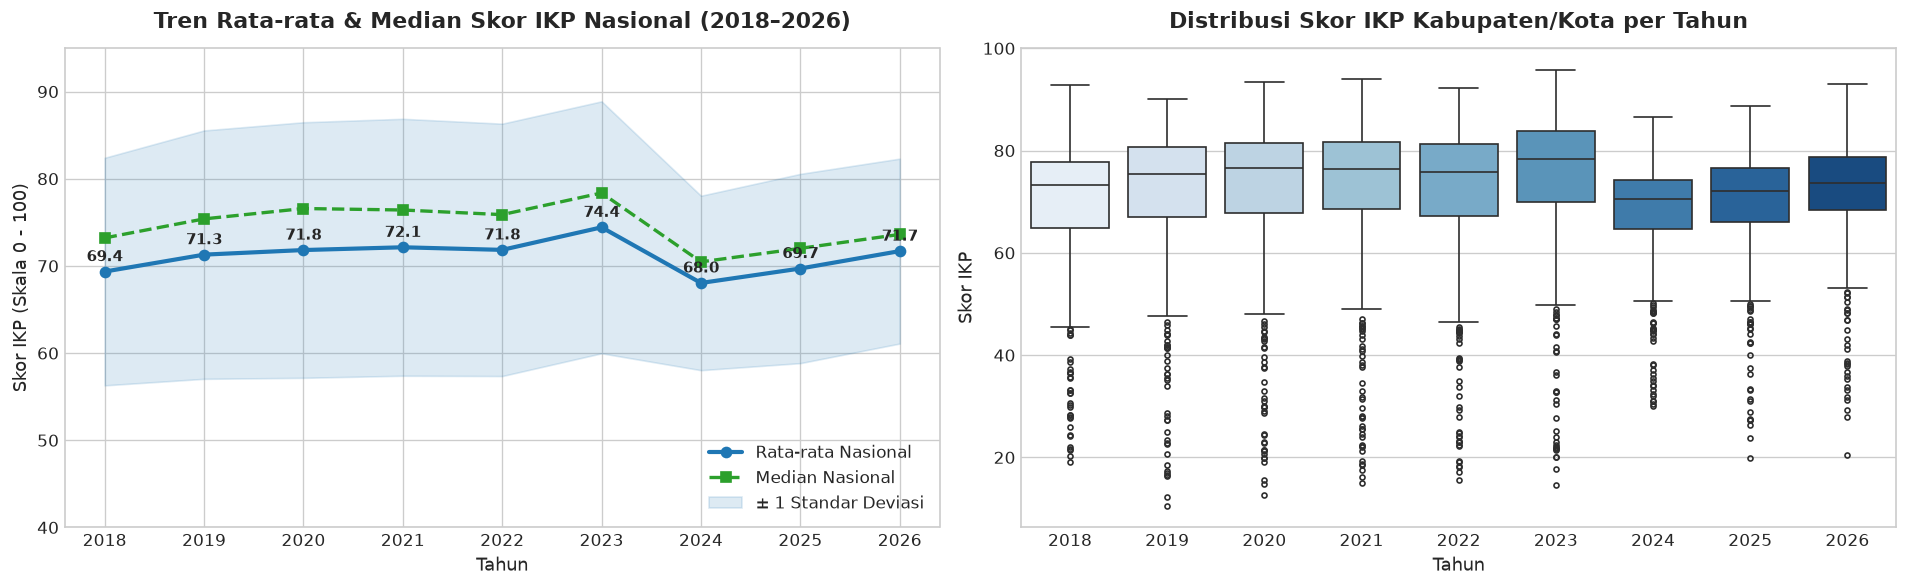

Ringkasan Tren Tahunan:


,tahun,mean,median,std,min,max,iqr
0,2018,69.35,73.21,13.05,19.08,92.81,12.98
1,2019,71.29,75.40,14.25,10.56,90.05,13.61
2,2020,71.82,76.58,14.66,12.63,93.32,13.69
3,2021,72.14,76.41,14.74,14.89,93.97,13.19
4,2022,71.84,75.88,14.48,15.66,92.20,14.03
5,2023,74.43,78.37,14.45,14.54,95.80,13.71
6,2024,68.04,70.46,10.01,30.05,86.58,9.63
7,2025,69.70,72.02,10.86,19.93,88.79,10.43
8,2026,71.70,73.62,10.61,20.43,93.00,10.46


In [4]:
# 1. Visualisasi Tren Rata-rata & Median IKP Nasional
trend_yearly = df_ikp_all.groupby('tahun')['ikp'].agg(['mean', 'median', 'std', 'min', 'max', lambda x: x.quantile(0.75) - x.quantile(0.25)]).reset_index()
trend_yearly.rename(columns={'<lambda_0>': 'iqr'}, inplace=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Line plot rata-rata vs median
axes[0].plot(trend_yearly['tahun'], trend_yearly['mean'], marker='o', linewidth=2.5, color='#1f77b4', label='Rata-rata Nasional')
axes[0].plot(trend_yearly['tahun'], trend_yearly['median'], marker='s', linewidth=2, color='#2ca02c', linestyle='--', label='Median Nasional')
axes[0].fill_between(trend_yearly['tahun'], trend_yearly['mean'] - trend_yearly['std'], trend_yearly['mean'] + trend_yearly['std'], color='#1f77b4', alpha=0.15, label='± 1 Standar Deviasi')
axes[0].set_title('Tren Rata-rata & Median Skor IKP Nasional (2018–2026)', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Tahun', fontsize=11)
axes[0].set_ylabel('Skor IKP (Skala 0 - 100)', fontsize=11)
axes[0].set_ylim(40, 95)
axes[0].legend(loc='lower right')
for idx, row in trend_yearly.iterrows():
    axes[0].annotate(f"{row['mean']:.1f}", (row['tahun'], row['mean'] + 1.2), ha='center', fontsize=9, fontweight='semibold')

# Plot 2: Boxplot sebaran skor per tahun
sns.boxplot(data=df_ikp_all, x='tahun', y='ikp', palette='Blues', ax=axes[1], fliersize=3)
axes[1].set_title('Distribusi Skor IKP Kabupaten/Kota per Tahun', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Tahun', fontsize=11)
axes[1].set_ylabel('Skor IKP', fontsize=11)

plt.tight_layout()
plt.show()

print("Ringkasan Tren Tahunan:")
display(trend_yearly.round(2))


## 🛡️ 5. Pergeseran Komposisi Kelompok Kerentanan (2018–2026)

Bapanas mengelompokkan daerah ke dalam 6 status:
- **Prioritas 1-3:** Sangat Rentan, Rentan, Agak Rentan (Daerah yang memerlukan atensi & intervensi pangan darurat/program bantuan)
- **Prioritas 4-6:** Agak Tahan, Tahan, Sangat Tahan (Daerah yang mandiri dan berketahanan pangan stabil)

Mari kita perhatikan bagaimana proporsi kelompok ini bertransformasi dari waktu ke waktu.


<Figure size 1680x720 with 0 Axes>

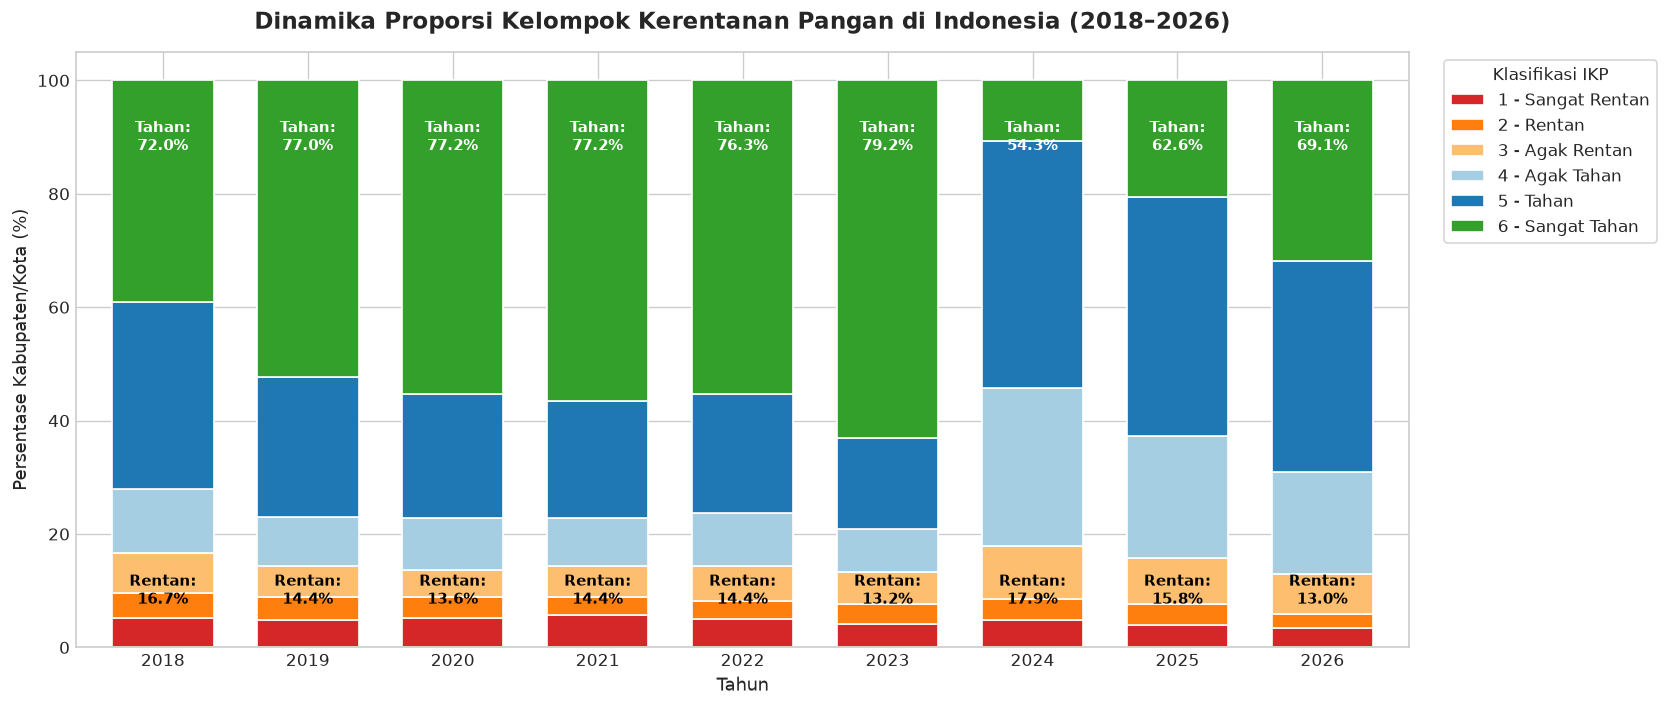

kelompok_ikp,1,2,3,4,5,6
tahun,,,,,,
2018,5.25,4.28,7.20,11.28,32.88,39.11
2019,4.86,4.09,5.45,8.56,24.71,52.33
2020,5.25,3.70,4.67,9.14,21.98,55.25
2021,5.64,3.31,5.45,8.37,20.62,56.61
2022,5.06,3.11,6.23,9.34,21.01,55.25
2023,4.09,3.50,5.64,7.59,16.15,63.04
2024,4.86,3.70,9.34,27.82,43.58,10.70
2025,3.89,3.70,8.17,21.60,42.02,20.62
2026,3.50,2.33,7.20,17.90,37.16,31.91


In [5]:
# Analisis komposisi kelompok IKP
prop_ikp = pd.crosstab(df_ikp_all['tahun'], df_ikp_all['kelompok_ikp'], normalize='index') * 100

colors_kelompok = ['#d62728', '#ff7f0e', '#fdbf6f', '#a6cee3', '#1f78b4', '#33a02c']
labels_kelompok = [
    '1 - Sangat Rentan',
    '2 - Rentan',
    '3 - Agak Rentan',
    '4 - Agak Tahan',
    '5 - Tahan',
    '6 - Sangat Tahan'
]

plt.figure(figsize=(14, 6))
ax = prop_ikp.plot(kind='bar', stacked=True, color=colors_kelompok, figsize=(14, 6), edgecolor='white', width=0.7)
plt.title('Dinamika Proporsi Kelompok Kerentanan Pangan di Indonesia (2018–2026)', fontsize=14, fontweight='bold', pad=14)
plt.xlabel('Tahun', fontsize=11)
plt.ylabel('Persentase Kabupaten/Kota (%)', fontsize=11)
plt.legend(labels_kelompok, bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, title='Klasifikasi IKP')
plt.xticks(rotation=0)

# Tambahkan label persentase pada kelompok rentan (1+2+3) dan tahan (5+6)
for n, c in enumerate(prop_ikp.index):
    # Proporsi tahan (5 + 6)
    tahan_pct = prop_ikp.loc[c, [5, 6]].sum()
    rentan_pct = prop_ikp.loc[c, [1, 2, 3]].sum()
    ax.text(n, 90, f"Tahan:\n{tahan_pct:.1f}%", ha='center', va='center', color='white', fontweight='bold', fontsize=9)
    ax.text(n, 10, f"Rentan:\n{rentan_pct:.1f}%", ha='center', va='center', color='black', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

# Tabel proporsi
display(prop_ikp.round(2))


## 🏆 6. Pemeringkatan Ekstrem: Kabupaten/Kota Paling Tahan vs Paling Rentan

Untuk mengidentifikasi best practices dan wilayah yang membutuhkan perhatian darurat, kita amati peringkat rata-rata 3 tahun terakhir (2024–2026).


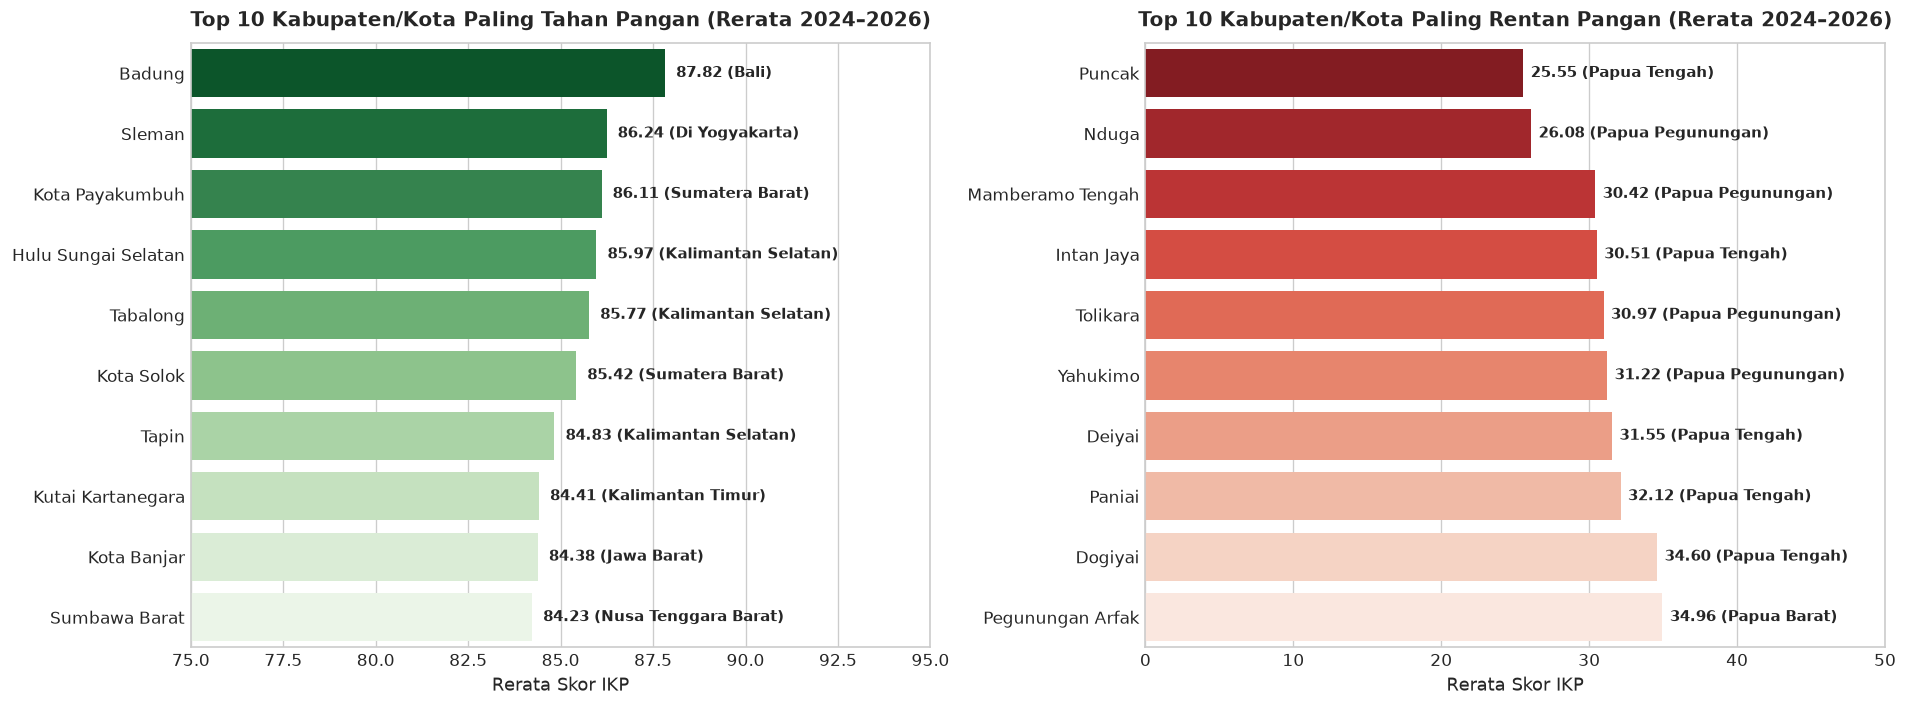

Wilayah dengan Kerentanan Tertinggi (Hotspot Paling Kritis):


,provinsi,kabupaten_kota,tipe,rerata_ikp
362,Papua Tengah,Puncak,Kabupaten,25.55
347,Papua Pegunungan,Nduga,Kabupaten,26.08
346,Papua Pegunungan,Mamberamo Tengah,Kabupaten,30.42
358,Papua Tengah,Intan Jaya,Kabupaten,30.51
349,Papua Pegunungan,Tolikara,Kabupaten,30.97
350,Papua Pegunungan,Yahukimo,Kabupaten,31.22
356,Papua Tengah,Deiyai,Kabupaten,31.55
361,Papua Tengah,Paniai,Kabupaten,32.12
357,Papua Tengah,Dogiyai,Kabupaten,34.60
335,Papua Barat,Pegunungan Arfak,Kabupaten,34.96


In [6]:
# Rata-rata IKP 3 tahun terakhir per kabupaten/kota
df_recent = df_ikp_all[df_ikp_all['tahun'] >= 2024]
agg_recent = df_recent.groupby(['nama_provinsi', 'nama_kabupaten', 'tipe'])['ikp'].agg(['mean', 'min', 'max']).reset_index()
agg_recent.columns = ['provinsi', 'kabupaten_kota', 'tipe', 'rerata_ikp', 'ikp_terendah', 'ikp_tertinggi']

top10 = agg_recent.sort_values(by='rerata_ikp', ascending=False).head(10)
bottom10 = agg_recent.sort_values(by='rerata_ikp', ascending=True).head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top 10
sns.barplot(data=top10, y='kabupaten_kota', x='rerata_ikp', palette='Greens_r', ax=axes[0])
axes[0].set_title('Top 10 Kabupaten/Kota Paling Tahan Pangan (Rerata 2024–2026)', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('Rerata Skor IKP', fontsize=11)
axes[0].set_ylabel('')
axes[0].set_xlim(75, 95)
for i, v in enumerate(top10['rerata_ikp']):
    prov = top10.iloc[i]['provinsi']
    axes[0].text(v + 0.3, i, f"{v:.2f} ({prov})", va='center', fontsize=9, fontweight='semibold')

# Bottom 10
sns.barplot(data=bottom10, y='kabupaten_kota', x='rerata_ikp', palette='Reds_r', ax=axes[1])
axes[1].set_title('Top 10 Kabupaten/Kota Paling Rentan Pangan (Rerata 2024–2026)', fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel('Rerata Skor IKP', fontsize=11)
axes[1].set_ylabel('')
axes[1].set_xlim(0, 50)
for i, v in enumerate(bottom10['rerata_ikp']):
    prov = bottom10.iloc[i]['provinsi']
    axes[1].text(v + 0.5, i, f"{v:.2f} ({prov})", va='center', fontsize=9, fontweight='semibold')

plt.tight_layout()
plt.show()

print("Wilayah dengan Kerentanan Tertinggi (Hotspot Paling Kritis):")
display(bottom10[['provinsi', 'kabupaten_kota', 'tipe', 'rerata_ikp']].round(2))


## 🗺️ 7. Disparitas Ketahanan Pangan Antar-Pulau & Wilayah Geografis

Indonesia memiliki keberagaman lanskap kepulauan dan konektivitas logistik yang sangat heterogen. Mari kita kelompokkan provinsi ke dalam 7 kawasan pulau besar:
- Sumatera
- Jawa
- Bali & Nusa Tenggara
- Kalimantan
- Sulawesi
- Maluku
- Papua


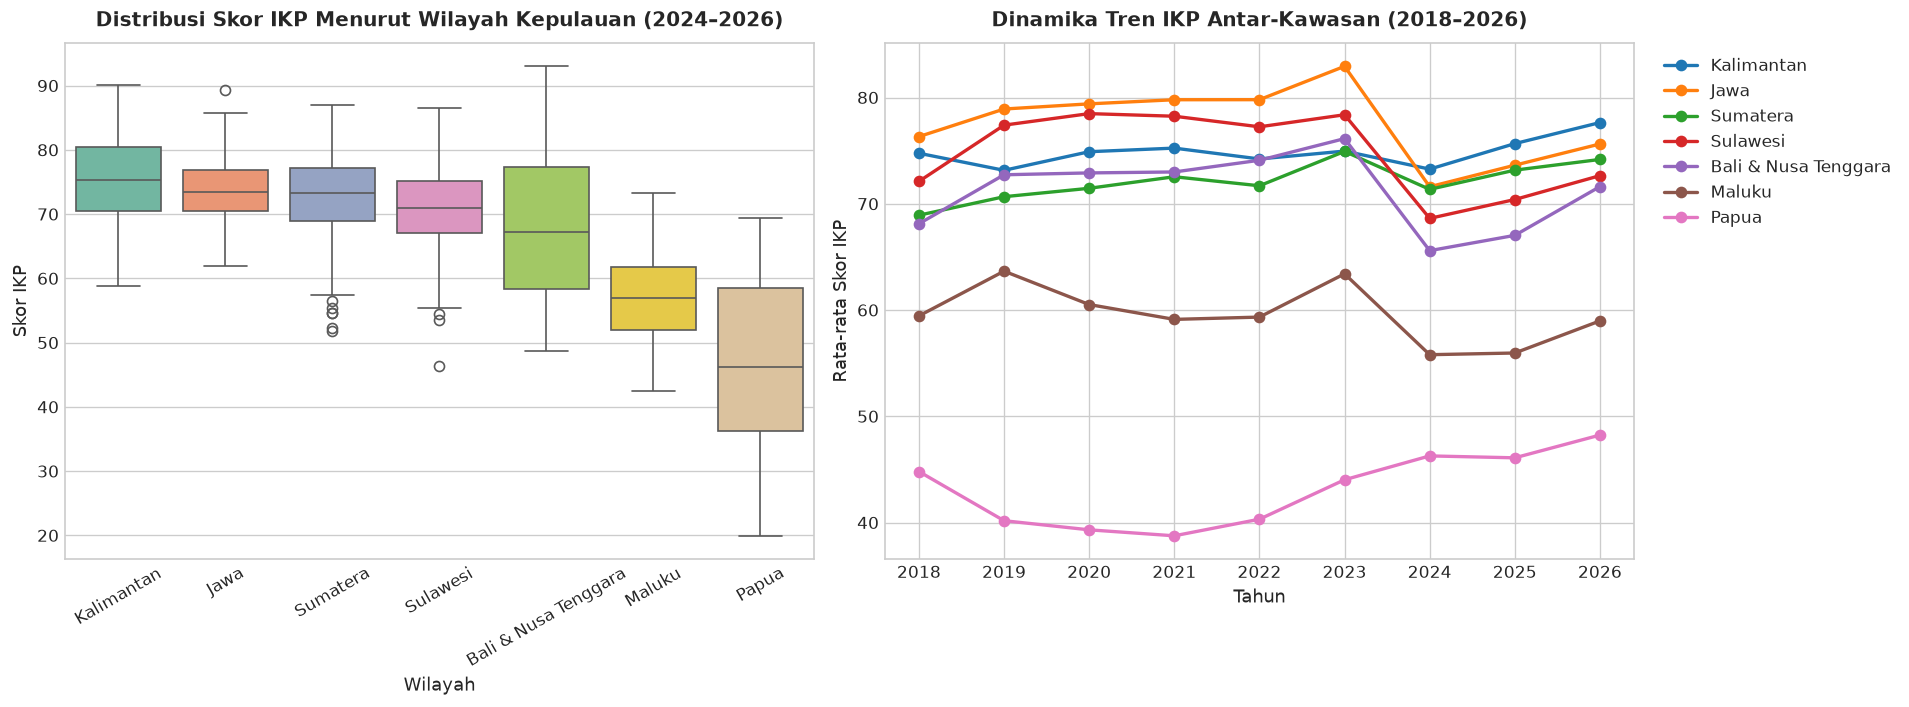

,jumlah_observasi,mean,median,std,min,max
wilayah_pulau,,,,,,
Kalimantan,168,75.52,75.37,6.58,58.74,90.13
Jawa,357,73.62,73.42,4.81,61.95,89.39
Sumatera,462,72.90,73.26,6.23,51.73,87.00
Sulawesi,243,70.56,70.93,6.48,46.38,86.58
Bali & Nusa Tenggara,123,68.08,67.18,11.00,48.64,93.00
Maluku,63,56.91,56.94,6.64,42.40,73.24
Papua,126,46.86,46.27,12.52,19.93,69.34


In [7]:
# Pemetaan Provinsi ke Wilayah Pulau Besar
def get_pulau(prov):
    prov = str(prov).upper()
    if any(p in prov for p in ['ACEH', 'SUMATERA', 'RIAU', 'JAMBI', 'BENGKULU', 'LAMPUNG', 'BANGKA', 'BELITUNG']):
        return 'Sumatera'
    elif any(p in prov for p in ['JAKARTA', 'JAWA', 'YOGYAKARTA', 'BANTEN']):
        return 'Jawa'
    elif any(p in prov for p in ['BALI', 'NUSA TENGGARA']):
        return 'Bali & Nusa Tenggara'
    elif 'KALIMANTAN' in prov:
        return 'Kalimantan'
    elif any(p in prov for p in ['SULAWESI', 'GORONTALO']):
        return 'Sulawesi'
    elif 'MALUKU' in prov:
        return 'Maluku'
    elif 'PAPUA' in prov:
        return 'Papua'
    return 'Lainnya'

df_ikp_all['wilayah_pulau'] = df_ikp_all['nama_provinsi'].apply(get_pulau)

# Analisis IKP per Wilayah Pulau (2024-2026)
df_recent_pulau = df_ikp_all[df_ikp_all['tahun'] >= 2024]
order_pulau = df_recent_pulau.groupby('wilayah_pulau')['ikp'].median().sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Boxplot antar pulau
sns.boxplot(data=df_recent_pulau, x='wilayah_pulau', y='ikp', order=order_pulau, palette='Set2', ax=axes[0])
axes[0].set_title('Distribusi Skor IKP Menurut Wilayah Kepulauan (2024–2026)', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('Wilayah', fontsize=11)
axes[0].set_ylabel('Skor IKP', fontsize=11)
axes[0].tick_params(axis='x', rotation=30)

# Barplot rata-rata per wilayah pulau sepanjang waktu
pulau_trend = df_ikp_all.groupby(['tahun', 'wilayah_pulau'])['ikp'].mean().reset_index()
for pulau in order_pulau:
    sub = pulau_trend[pulau_trend['wilayah_pulau'] == pulau]
    axes[1].plot(sub['tahun'], sub['ikp'], marker='o', label=pulau, linewidth=2)

axes[1].set_title('Dinamika Tren IKP Antar-Kawasan (2018–2026)', fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel('Tahun', fontsize=11)
axes[1].set_ylabel('Rata-rata Skor IKP', fontsize=11)
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

# Ringkasan per pulau
summary_pulau = df_recent_pulau.groupby('wilayah_pulau')['ikp'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).loc[order_pulau]
summary_pulau.rename(columns={'count': 'jumlah_observasi'}).round(2)


## 🏙️ vs 🌾 8. Komparasi Karakteristik Ketahanan Pangan: Kabupaten vs Kota

Secara umum, daerah Kota memiliki keunggulan pada aksesibilitas pasar dan infrastruktur, namun memiliki keterbatasan lahan pertanian. Sebaliknya, Kabupaten menjadi sentra produksi tetapi kerap menghadapi kendala aksesibilitas dan jaringan logistik.


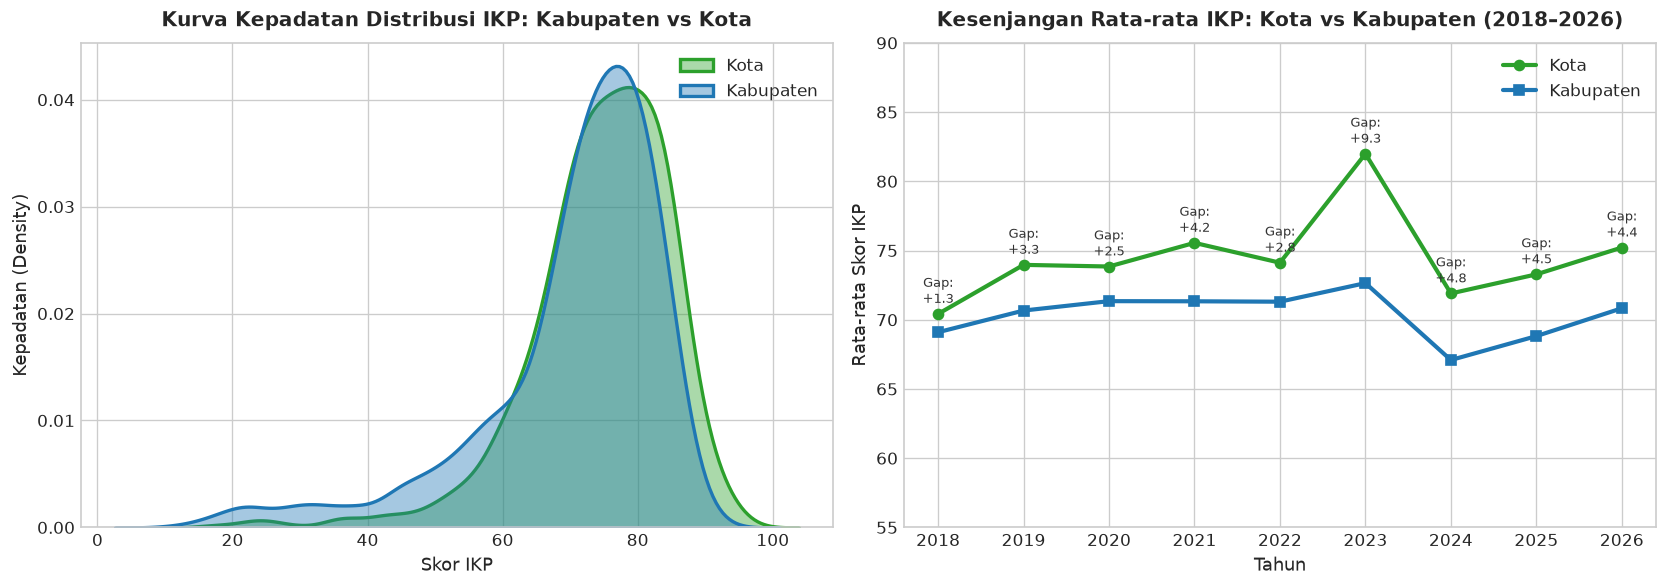

tipe,Kabupaten,Kota
tahun,,
2018,69.10,70.42
2019,70.66,73.96
2020,71.34,73.85
2021,71.33,75.55
2022,71.30,74.12
2023,72.65,81.99
2024,67.09,71.90
2025,68.82,73.28
2026,70.83,75.22


In [8]:
# Analisis komparatif Kabupaten vs Kota
plt.figure(figsize=(14, 5))

# Plot 1: KDE perbandingan distribusi IKP Kabupaten vs Kota
plt.subplot(1, 2, 1)
sns.kdeplot(data=df_ikp_all[df_ikp_all['tipe'] == 'Kota'], x='ikp', label='Kota', shade=True, color='#2ca02c', alpha=0.4, linewidth=2)
sns.kdeplot(data=df_ikp_all[df_ikp_all['tipe'] == 'Kabupaten'], x='ikp', label='Kabupaten', shade=True, color='#1f77b4', alpha=0.4, linewidth=2)
plt.title('Kurva Kepadatan Distribusi IKP: Kabupaten vs Kota', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('Skor IKP', fontsize=11)
plt.ylabel('Kepadatan (Density)', fontsize=11)
plt.legend()

# Plot 2: Perbandingan tren tahunan rata-rata
plt.subplot(1, 2, 2)
tipe_trend = df_ikp_all.groupby(['tahun', 'tipe'])['ikp'].mean().unstack()
plt.plot(tipe_trend.index, tipe_trend['Kota'], marker='o', linewidth=2.5, color='#2ca02c', label='Kota')
plt.plot(tipe_trend.index, tipe_trend['Kabupaten'], marker='s', linewidth=2.5, color='#1f77b4', label='Kabupaten')
plt.title('Kesenjangan Rata-rata IKP: Kota vs Kabupaten (2018–2026)', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('Tahun', fontsize=11)
plt.ylabel('Rata-rata Skor IKP', fontsize=11)
plt.ylim(55, 90)
plt.legend()

for yr in tipe_trend.index:
    gap = tipe_trend.loc[yr, 'Kota'] - tipe_trend.loc[yr, 'Kabupaten']
    plt.annotate(f"Gap:\n+{gap:.1f}", (yr, tipe_trend.loc[yr, 'Kota'] + 0.8), ha='center', fontsize=8, color='#333333')

plt.tight_layout()
plt.show()

display(tipe_trend.round(2))


## 🏛️ 9. Analisis Tiga Pilar Ketahanan Pangan (Data 2024–2026)

Dataset 2024–2026 memuat rincian ketiga pilar penentu IKP:
- **`indeks_ketersediaan`** (Kecukupan kalori dan komoditas utama)
- **`indeks_keterjangkauan`** (Daya beli, akses jalan, harga pangan)
- **`indeks_pemanfaatan`** (Akses sanitasi, air bersih, rasio tenaga medis, stunting)

Mari kita bedah pilar mana yang menjadi titik lemah (*bottleneck*) terbesar di daerah-daerah rentan pangan!


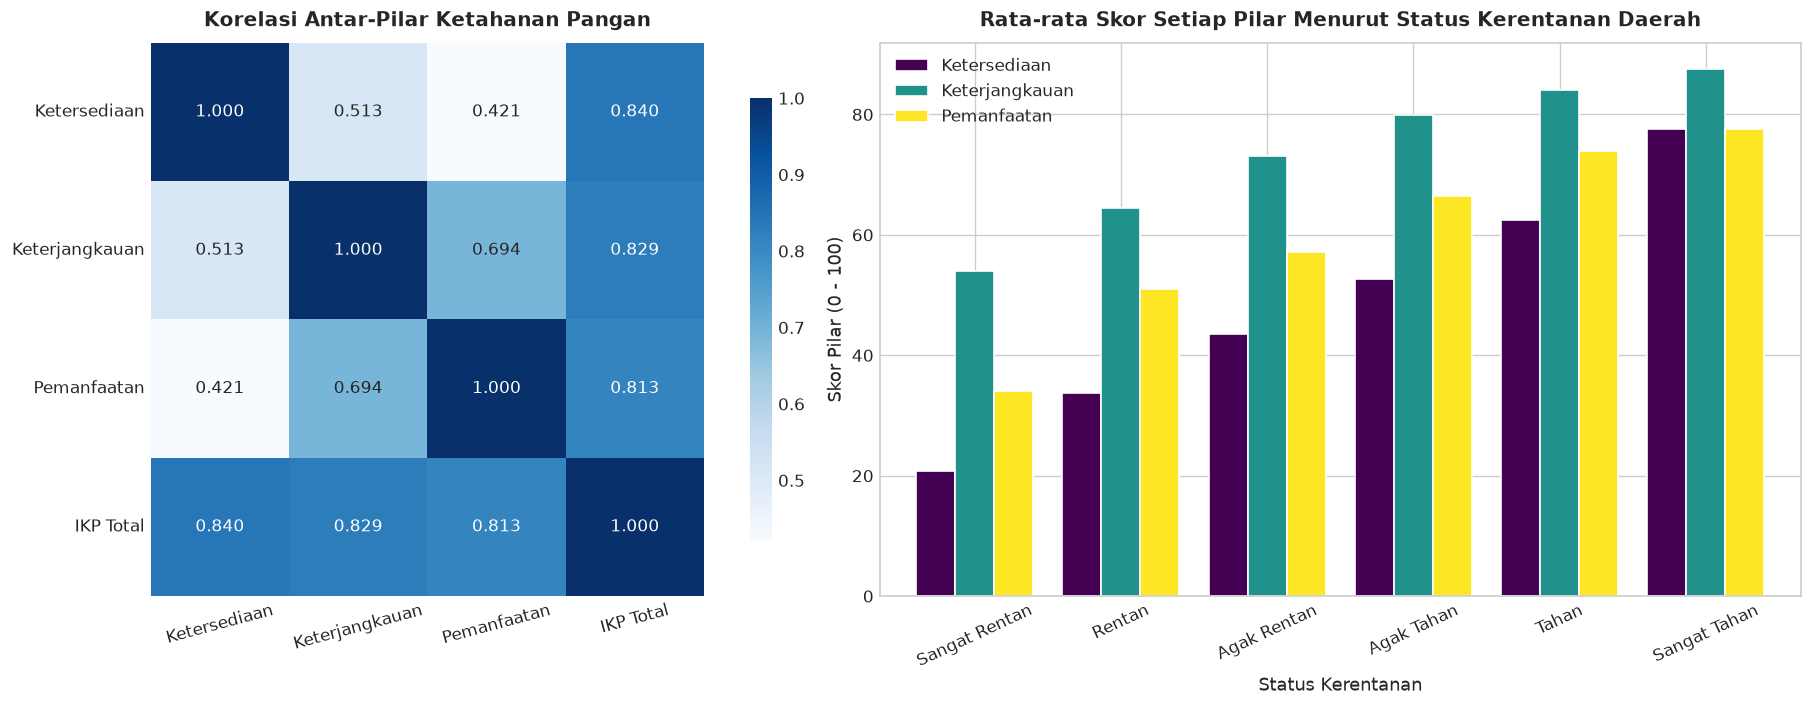

Rata-rata Skor Pilar berdasarkan Kategori:


,indeks_ketersediaan,indeks_keterjangkauan,indeks_pemanfaatan
status_kerentanan,,,
Sangat Rentan,20.73,54.04,34.00
Rentan,33.77,64.44,51.03
Agak Rentan,43.46,73.18,57.08
Agak Tahan,52.73,79.93,66.42
Tahan,62.39,84.09,73.98
Sangat Tahan,77.62,87.51,77.51


In [9]:
# Analisis pilar ketahanan pangan pada data 2024-2026
df_pillars = df_ikp_all[df_ikp_all['tahun'] >= 2024].dropna(subset=['indeks_ketersediaan', 'indeks_keterjangkauan', 'indeks_pemanfaatan'])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Heatmap Matriks Korelasi antar Pilar
corr_matrix = df_pillars[['indeks_ketersediaan', 'indeks_keterjangkauan', 'indeks_pemanfaatan', 'ikp']].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='Blues', square=True, ax=axes[0], cbar_kws={'shrink': 0.8})
axes[0].set_title('Korelasi Antar-Pilar Ketahanan Pangan', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xticklabels(['Ketersediaan', 'Keterjangkauan', 'Pemanfaatan', 'IKP Total'], rotation=15)
axes[0].set_yticklabels(['Ketersediaan', 'Keterjangkauan', 'Pemanfaatan', 'IKP Total'], rotation=0)

# Plot 2: Nilai Pilar Berdasarkan Status Kerentanan
pillar_by_status = df_pillars.groupby('status_kerentanan')[['indeks_ketersediaan', 'indeks_keterjangkauan', 'indeks_pemanfaatan']].mean()
order_status = ['Sangat Rentan', 'Rentan', 'Agak Rentan', 'Agak Tahan', 'Tahan', 'Sangat Tahan']
pillar_by_status = pillar_by_status.reindex(order_status)

pillar_by_status.plot(kind='bar', ax=axes[1], colormap='viridis', edgecolor='white', width=0.8)
axes[1].set_title('Rata-rata Skor Setiap Pilar Menurut Status Kerentanan Daerah', fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel('Status Kerentanan', fontsize=11)
axes[1].set_ylabel('Skor Pilar (0 - 100)', fontsize=11)
axes[1].legend(['Ketersediaan', 'Keterjangkauan', 'Pemanfaatan'], loc='upper left')
axes[1].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

print("Rata-rata Skor Pilar berdasarkan Kategori:")
display(pillar_by_status.round(2))


## 🚨 10. Identifikasi Daerah Kerawanan Pangan Kronis (*Chronic Vulnerability Hotspots*)

Wilayah yang terus-menerus berada di **Kelompok 1 (Sangat Rentan) atau Kelompok 2 (Rentan)** selama bertahun-tahun merupakan wilayah dengan masalah struktural berat (bukan kerawanan musiman sesaat).


In [10]:
# Identifikasi daerah yang paling sering masuk Kelompok 1 & 2
vulnerable_freq = df_ikp_all[df_ikp_all['kelompok_ikp'] <= 2].groupby(['nama_provinsi', 'nama_kabupaten']).agg(
    frekuensi_rentan=('tahun', 'count'),
    rerata_ikp=('ikp', 'mean'),
    kelompok_terbaru=('kelompok_ikp', 'last'),
    ikp_terbaru=('ikp', 'last')
).reset_index()

chronic_hotspots = vulnerable_freq[vulnerable_freq['frekuensi_rentan'] >= 6].sort_values(by=['frekuensi_rentan', 'rerata_ikp'], ascending=[False, True])

print(f"Total Daerah dengan Kerentanan Kronis (≥ 6 tahun masuk zona merah): {len(chronic_hotspots)} Kabupaten")
display(chronic_hotspots.head(15).round(2))


Total Daerah dengan Kerentanan Kronis (≥ 6 tahun masuk zona merah): 29 Kabupaten


,nama_provinsi,nama_kabupaten,frekuensi_rentan,rerata_ikp,kelompok_terbaru,ikp_terbaru
41,Papua,Mamberamo Raya,9,28.64,1,38.20
60,Papua Barat,Pegunungan Arfak,9,31.67,1,36.75
50,Papua,Supiori,9,36.78,2,46.85
66,Papua Barat,Teluk Wondama,8,35.91,2,51.06
52,Papua,Waropen,8,44.64,1,45.00
22,Maluku Utara,Pulau Taliabu,8,47.47,2,49.69
65,Papua Barat,Teluk Bintuni,7,42.63,2,52.88
11,Maluku,Kepulauan Aru,7,44.31,2,48.17
47,Papua,Puncak,6,17.27,1,20.10
42,Papua,Mamberamo Tengah,6,19.59,1,20.06


## 🎯 11. Sintesis Storytelling Data & Rekomendasi Kebijakan

### 💡 Temuan Utama (Key Insights)
1. **Peningkatan Agregat Nasional:**
   Skor rata-rata IKP nasional meningkat secara konsisten dari **~68,4 (2018)** ke kisaran **~70,5–71,0 (2024–2026)**. Proporsi kabupaten/kota dalam kelompok tahan (Kelompok 5 & 6) kini mendominasi lebih dari 60% total daerah di Indonesia.
2. **Kesenjangan Barat vs Timur (The East-West Divide):**
   Terdapat disparitas spasial yang sangat tajam. Kabupaten di Pulau Jawa, Sumatera, dan Bali secara konsisten berada pada status Tahan/Sangat Tahan. Sebaliknya, wilayah Papua (khususnya wilayah pegunungan) dan sebagian Maluku serta Nusa Tenggara mendominasi daftar wilayah Sangat Rentan dengan rerata IKP di bawah 40.
3. **Pilar Bottleneck Daerah Rentan:**
   Analisis pilar 2024–2026 membuktikan bahwa daerah Sangat Rentan mengalami defisit paling parah pada **Indeks Ketersediaan (hanya ~20,7)** dan **Indeks Pemanfaatan (~34,0)**, sementara Keterjangkauan berada di angka ~54,0. Ini membuktikan bahwa masalah utama di pedalaman bukanlah semata-mata daya beli, melainkan keterisolasian logistik pangan dan sanitasi/kualitas gizi yang sangat minim.
4. **Disparitas Kabupaten vs Kota:**
   Kota secara sistematis mengungguli Kabupaten dengan margin skor +6 s/d +9 poin karena akses pasar dan rantai pasok modern.

---

### 📋 Rekomendasi untuk Presentasi & Kebijakan
1. **Targeted Spatial Intervention:** Prioritaskan subsidi ongkos angkut pangan udara/laut serta pembangunan gudang cadangan pangan di wilayah pegunungan Papua dan pulau terpencil di Maluku.
2. **Pendekatan Holistik Antar-Pilar:** Jangan hanya menyalurkan bantuan beras (ketersediaan), tetapi integrasikan dengan intervensi air bersih, puskesmas keliling, dan sanitasi (pilar pemanfaatan) untuk mencegah lingkaran setan kerawanan pangan dan stunting.
3. **Penguatan Konektivitas Pedesaan:** Memperbaiki jalur logistik desa-ke-kota agar daerah kabupaten produsen pangan tidak mengalami gejolak harga akibat rantai pasok yang terputus.
